# Time Series Forecasting – Retail Sales

This notebook builds and evaluates forecasting models for daily retail sales.
A baseline statistical model is compared with a production-oriented forecasting model to justify the final choice for deployment.


In [1]:
import warnings
import logging
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from prophet import Prophet
from prophet.serialize import model_to_json
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX

from sklearn.metrics import mean_absolute_error, mean_squared_error

warnings.filterwarnings('ignore')
logging.getLogger('cmdstanpy').setLevel(logging.ERROR)

OUT = Path('../outputs')
OUT.mkdir(exist_ok=True)

.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Importing plotly failed. Interactive plots will not work.


### Load Processed Time Series

The processed dataset ensures consistency between exploratory analysis and model training, avoiding duplicate preprocessing logic.


In [2]:
ts_df = pd.read_csv("../data/processed_store1.csv")
ts_df['ds'] = pd.to_datetime(ts_df['ds'])
ts_df = ts_df.sort_values('ds')

ts_df.head(10)


,ds,y,Open,Promo,StateHoliday,SchoolHoliday
0,2013-01-01,0,0,0,1,1
1,2013-01-02,5530,1,0,0,1
2,2013-01-03,4327,1,0,0,1
3,2013-01-04,4486,1,0,0,1
4,2013-01-05,4997,1,0,0,1
5,2013-01-06,0,0,0,0,1
6,2013-01-07,7176,1,1,0,1
7,2013-01-08,5580,1,1,0,1
8,2013-01-09,5471,1,1,0,1
9,2013-01-10,4892,1,1,0,1


### Train–Validation Split

A time-based train–validation split is used to simulate real-world forecasting,
where models are trained on historical data and evaluated on future unseen observations.



In [3]:
train_size = int(len(ts_df) * 0.8)

train_df = ts_df.iloc[:train_size]
val_df = ts_df.iloc[train_size:]


### Baseline Model: ARIMA

ARIMA is used solely as a statistical baseline.
Its limitations in handling multiple seasonal patterns motivate the use of more flexible forecasting models.


In [4]:
arima_model = ARIMA(train_df['y'], order=(1,1,1))
arima_result = arima_model.fit()

arima_forecast = arima_result.forecast(steps=len(val_df))


### Baseline Evaluation

The ARIMA model provides a reference performance level for comparison.


In [5]:
arima_mae = mean_absolute_error(val_df['y'], arima_forecast)
arima_rmse = np.sqrt(mean_squared_error(val_df['y'], arima_forecast))

arima_mae, arima_rmse


(1321.0949265838535, np.float64(1892.002197065241))

### Prophet Forecasting Model (no regressors)

Plain Prophet with weekly and yearly seasonality only. It is not told about store closures, promotions or holidays.

In [6]:
prophet_model = Prophet(
    weekly_seasonality=True,
    yearly_seasonality=True,
    daily_seasonality=False
)

prophet_model.fit(train_df)


19:27:09 - cmdstanpy - INFO - Chain [1] start processing


19:27:09 - cmdstanpy - INFO - Chain [1] done processing


In [7]:
future = prophet_model.make_future_dataframe(periods=len(val_df))
forecast = prophet_model.predict(future)

forecast[['ds', 'yhat']].tail()


,ds,yhat
937,2015-07-27,4974.035731
938,2015-07-28,4587.205004
939,2015-07-29,4346.379025
940,2015-07-30,3969.396613
941,2015-07-31,4459.586263


### Prophet Evaluation

The Prophet model consistently outperforms the ARIMA baseline across error metrics,
demonstrating improved pattern learning and justifying its selection as the final model.


In [8]:
prophet_pred = forecast.iloc[-len(val_df):]['yhat']

prophet_mae = mean_absolute_error(val_df['y'], prophet_pred)
prophet_rmse = np.sqrt(mean_squared_error(val_df['y'], prophet_pred))

prophet_mae, prophet_rmse


(701.4127289266899, np.float64(1083.3631123096054))

### Model Comparison

Prophet demonstrates lower forecasting error compared to ARIMA, justifying its selection as the final model.


In [9]:
comparison = pd.DataFrame({
    "Model": ["ARIMA", "Prophet"],
    "MAE": [arima_mae, prophet_mae],
    "RMSE": [arima_rmse, prophet_rmse]
})

comparison


,Model,MAE,RMSE
0,ARIMA,1321.094927,1892.002197
1,Prophet,701.412729,1083.363112


### Forecast vs Actual Plot
The forecast closely follows the overall trend and seasonality of actual sales.
Some deviation is expected due to promotion-driven spikes and daily-level volatility.


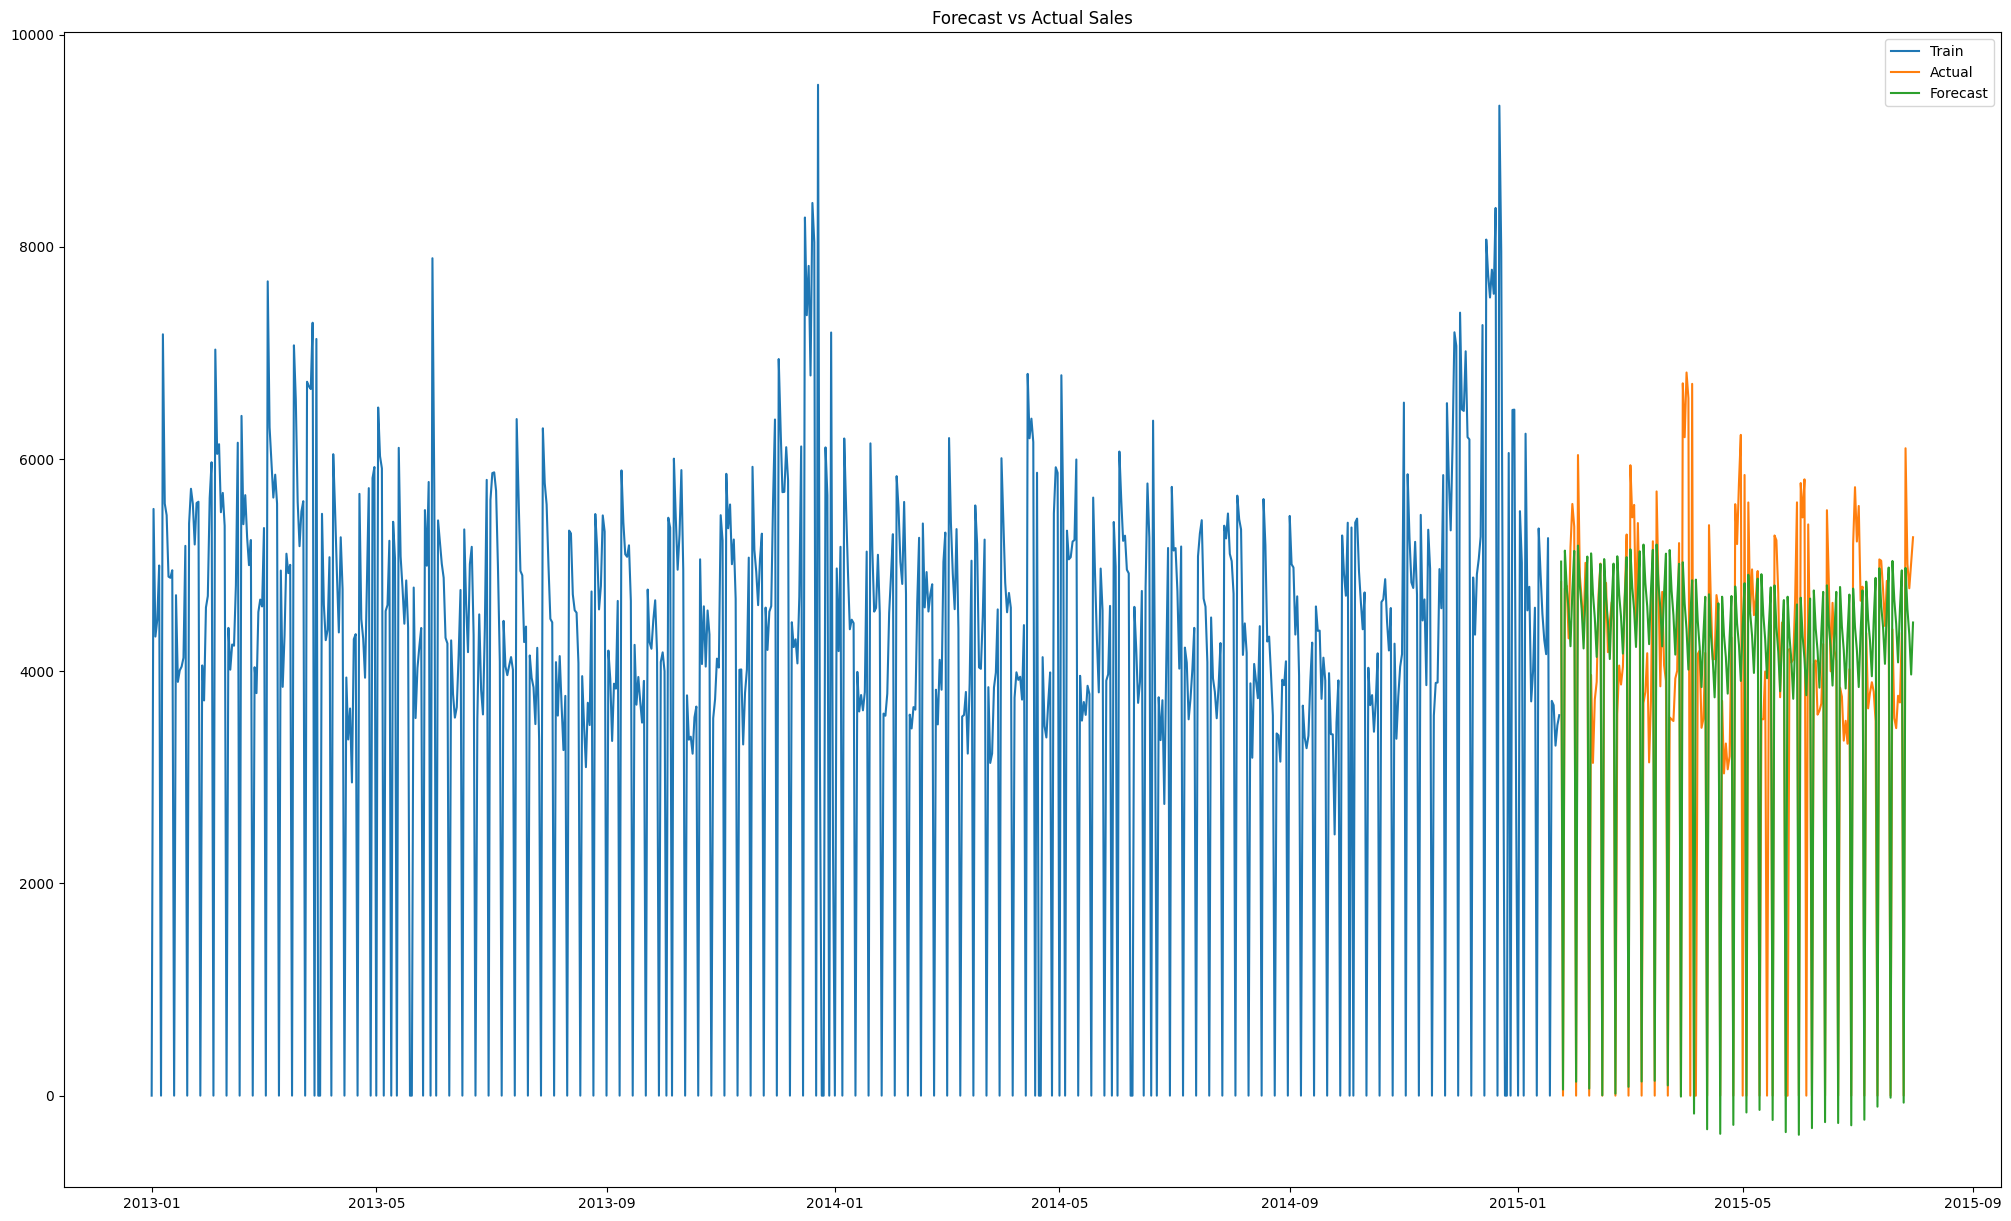

In [10]:
plt.figure(figsize=(25,15))
plt.plot(train_df['ds'], train_df['y'], label="Train")
plt.plot(val_df['ds'], val_df['y'], label="Actual")
plt.plot(val_df['ds'], prophet_pred.values, label="Forecast")
plt.legend()
plt.title("Forecast vs Actual Sales")
plt.show()


### SMAPE Evaluation

The Prophet model achieved a SMAPE of approximately 46.7%, outperforming the ARIMA baseline.  
Given the presence of structural zero-sales days and promotion-driven volatility, this level of error is considered acceptable for daily retail demand forecasting.

The relative improvement over the baseline demonstrates the model’s ability to capture key temporal patterns.


In [11]:
def smape(y_true, y_pred):
    return 100 * np.mean(
        2 * np.abs(y_pred - y_true) / (np.abs(y_true) + np.abs(y_pred) + 1e-8)
    )

prophet_smape = smape(val_df['y'], prophet_pred)
arima_smape = smape(val_df['y'], arima_forecast)

arima_smape, prophet_smape



(np.float64(48.768566807113004), np.float64(46.748492686819084))

Although absolute error values appear high, they must be interpreted relative to the scale of daily sales
and the presence of structural zero-sales days due to store closures.

Prophet achieved consistent improvement over the baseline across RMSE, MAE, and SMAPE,
indicating better capture of weekly seasonality and business-driven patterns.


## Improved models

The first Prophet run does not know that the store is closed on Sundays, so it predicts roughly 4,000 on days where the true value is 0. That alone inflates MAE, RMSE and especially SMAPE. This section fixes the baseline comparison and the model:

1. **SARIMA** (seasonal period 7), a fair statistical baseline, since plain ARIMA cannot represent the weekly cycle.
2. **Seasonal naive** (same weekday last week), the minimum bar any model must beat.
3. **Prophet with regressors**: `Open`, `Promo`, `StateHoliday`, `SchoolHoliday`. These are known in advance (they are provided in `test.csv`), so using them is not leakage.
4. **Closed-day masking**: when `Open == 0` the forecast is set to 0 and predictions are clipped at 0.
5. **RMSPE** (the Kaggle metric for this competition), computed on open days only because it divides by the actual value.

In [12]:
regressors = ['Open', 'Promo', 'StateHoliday', 'SchoolHoliday']

def smape(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true, float), np.asarray(y_pred, float)
    return 100 * np.mean(2 * np.abs(y_pred - y_true) / (np.abs(y_true) + np.abs(y_pred) + 1e-8))

def rmspe(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true, float), np.asarray(y_pred, float)
    m = y_true > 0
    return np.sqrt(np.mean(((y_true[m] - y_pred[m]) / y_true[m]) ** 2))

def scores(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true, float), np.asarray(y_pred, float)
    return {
        'MAE': mean_absolute_error(y_true, y_pred),
        'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
        'SMAPE %': smape(y_true, y_pred),
        'RMSPE (open days)': rmspe(y_true, y_pred),
    }

def fit_prophet_reg(train):
    m = Prophet(weekly_seasonality=True, yearly_seasonality=True, daily_seasonality=False)
    for r in regressors:
        m.add_regressor(r)
    m.fit(train)
    return m

def mask_closed(pred, open_flag):
    return np.where(np.asarray(open_flag) == 1, np.clip(pred, 0, None), 0.0)

### SARIMA baseline

In [13]:
sarima = SARIMAX(train_df['y'], order=(1, 1, 1), seasonal_order=(1, 1, 1, 7)).fit(disp=False)
sarima_forecast = sarima.forecast(steps=len(val_df)).values

### Seasonal naive baseline

Forecast = the value from the same weekday one week earlier (uses only past actuals).

In [14]:
full_y = ts_df['y'].values
naive_forecast = full_y[train_size - 7: len(full_y) - 7]
assert len(naive_forecast) == len(val_df)

### Prophet with regressors, with and without closed-day masking

In [15]:
prophet_reg = fit_prophet_reg(train_df)
reg_raw = prophet_reg.predict(val_df[['ds'] + regressors])['yhat'].values
reg_masked = mask_closed(reg_raw, val_df['Open'])

19:27:14 - cmdstanpy - INFO - Chain [1] start processing


19:27:14 - cmdstanpy - INFO - Chain [1] done processing


### Model comparison (validation set, last 20% of days)

In [16]:
results = pd.DataFrame({
    'ARIMA(1,1,1)': scores(val_df['y'], arima_forecast),
    'Seasonal naive (t-7)': scores(val_df['y'], naive_forecast),
    'SARIMA(1,1,1)(1,1,1,7)': scores(val_df['y'], sarima_forecast),
    'Prophet (no regressors)': scores(val_df['y'], prophet_pred.values),
    'Prophet + regressors': scores(val_df['y'], reg_raw),
    'Prophet + regressors + closed-day mask': scores(val_df['y'], reg_masked),
}).T.round(3)
results

,MAE,RMSE,SMAPE %,RMSPE (open days)
"ARIMA(1,1,1)",1321.095,1892.002,48.769,0.184
Seasonal naive (t-7),1198.101,1685.432,32.645,0.356
"SARIMA(1,1,1)(1,1,1,7)",696.823,1101.977,46.979,0.189
Prophet (no regressors),701.413,1083.363,46.748,0.184
Prophet + regressors,433.658,561.236,43.626,0.139
Prophet + regressors + closed-day mask,400.693,549.963,8.706,0.139


**How to read this table.** The big jump from ARIMA to the other models comes largely from *seasonality*, not from Prophet itself: SARIMA is far better than non-seasonal ARIMA. Prophet with calendar regressors and closed-day masking is the best model, and the SMAPE drop is large because closed days are now predicted as exactly 0.

### Rolling-origin backtest

A single 80/20 split can be lucky or unlucky. Here the last 5 windows of 48 days (the length of the real test horizon) are each forecast from data that ends before the window starts.

In [17]:
horizon, n_folds = 48, 5
rows = []
for k in range(n_folds, 0, -1):
    end = len(ts_df) - (k - 1) * horizon
    tr, te = ts_df.iloc[:end - horizon], ts_df.iloc[end - horizon:end]
    m = fit_prophet_reg(tr)
    p = mask_closed(m.predict(te[['ds'] + regressors])['yhat'].values, te['Open'])
    s = SARIMAX(tr['y'], order=(1, 1, 1), seasonal_order=(1, 1, 1, 7)).fit(disp=False).forecast(horizon).values
    nv = ts_df['y'].values[end - horizon - 7:end - 7]
    for name, pred in [('Prophet + regressors + mask', p), ('SARIMA', s), ('Seasonal naive', nv)]:
        rows.append({'fold': n_folds - k + 1, 'window_start': te['ds'].iloc[0].date(), 'model': name, **scores(te['y'], pred)})

cv = pd.DataFrame(rows)
cv.groupby('model')[['MAE', 'RMSE', 'SMAPE %', 'RMSPE (open days)']].agg(['mean', 'std']).round(3)

19:27:15 - cmdstanpy - INFO - Chain [1] start processing


19:27:15 - cmdstanpy - INFO - Chain [1] done processing


19:27:19 - cmdstanpy - INFO - Chain [1] start processing


19:27:19 - cmdstanpy - INFO - Chain [1] done processing


19:27:23 - cmdstanpy - INFO - Chain [1] start processing


...

19:27:27 - cmdstanpy - INFO - Chain [1] start processing


19:27:27 - cmdstanpy - INFO - Chain [1] done processing


19:27:32 - cmdstanpy - INFO - Chain [1] start processing


19:27:32 - cmdstanpy - INFO - Chain [1] done processing


MAE               RMSE          SMAPE %  \
                                 mean      std      mean      std    mean   
model                                                                       
Prophet + regressors + mask   443.387  146.839   621.762  223.231   9.174   
SARIMA                        864.016  367.962  1203.763  526.281  49.329   
Seasonal naive               1282.983  403.993  1751.876  645.292  33.249   

                                    RMSPE (open days)         
                                std              mean    std  
model                                                         
Prophet + regressors + mask   2.305             0.150  0.047  
SARIMA                        8.358             0.209  0.054  
Seasonal naive               14.069             0.358  0.090

Fold-level numbers are in the `cv` DataFrame. A model is only trusted here if it wins on average and the spread across folds is small relative to the gap.

### Limitations and Future Improvements

Addressed above: regressors, closed-day masking, SARIMA and seasonal-naive baselines, RMSPE, rolling-origin backtest.

Still open:
- Only one store is modelled. A global model over all 1,115 stores (for example gradient boosting with lag features and store metadata) would match the full Kaggle task.
- Holiday handling is limited to the `StateHoliday` flag; named holidays and the Easter/Christmas distinction are not modelled.
- Promo effect is assumed additive; a multiplicative mode may fit better.
- Model performance monitoring would be required in a production environment.

# Weekly Sales Forecasting (Business-Level View)


Daily sales are aggregated to weekly totals to reduce noise and align with business-level demand planning and reporting.


In [18]:
weekly_df = (
    ts_df
    .set_index('ds')[['y']]
    .resample('W-SUN')
    .sum()
    .reset_index()
)

weekly_df.rename(columns={'ds': 'ds', 'y': 'y'}, inplace=True)
weekly_df.head()


,ds,y
0,2013-01-06,19340
1,2013-01-13,32952
2,2013-01-20,25978
3,2013-01-27,33071
4,2013-02-03,28693


A time-based split is applied to weekly aggregated data to evaluate forecasting performance on future periods.


In [19]:
train_size = int(len(weekly_df) * 0.8)

weekly_train = weekly_df.iloc[:train_size]
weekly_val = weekly_df.iloc[train_size:]


Prophet is trained on weekly aggregated data to capture long-term seasonal patterns while minimizing daily volatility.


In [20]:
weekly_model = Prophet(
    weekly_seasonality=False,
    yearly_seasonality=True
)

weekly_model.fit(weekly_train)


19:27:37 - cmdstanpy - INFO - Chain [1] start processing


19:27:37 - cmdstanpy - INFO - Chain [1] done processing


In [21]:
future_weekly = weekly_model.make_future_dataframe(periods=len(weekly_val), freq='W')
weekly_forecast = weekly_model.predict(future_weekly)


In [22]:
weekly_pred = weekly_forecast.iloc[-len(weekly_val):]['yhat']

weekly_mae = mean_absolute_error(weekly_val['y'], weekly_pred)
weekly_rmse = np.sqrt(mean_squared_error(weekly_val['y'], weekly_pred))

weekly_mae, weekly_rmse


(2984.2520081202956, np.float64(3416.4374152858322))

In [23]:
weekly_naive = weekly_df['y'].shift(1).iloc[train_size:]   # previous week's total
weekly_naive_mae = mean_absolute_error(weekly_val['y'], weekly_naive)
print(f'Weekly Prophet MAE: {weekly_mae:.0f} | Weekly naive (last week) MAE: {weekly_naive_mae:.0f}')
print(f"Mean weekly sales (validation): {weekly_val['y'].mean():.0f} -> Prophet MAE is {100 * weekly_mae / weekly_val['y'].mean():.1f}% of the mean")

Weekly Prophet MAE: 2984 | Weekly naive (last week) MAE: 5684
Mean weekly sales (validation): 26026 -> Prophet MAE is 11.5% of the mean


Weekly aggregation significantly reduces day-to-day noise and improves forecast stability.
This view is more suitable for business planning, inventory management, and executive reporting.

While daily forecasts support operational monitoring, weekly forecasts provide clearer demand trends and improved predictive accuracy.


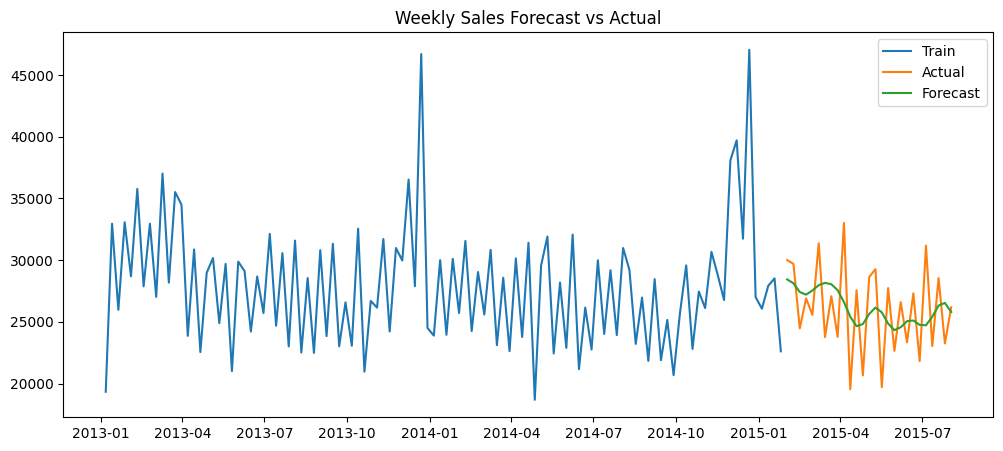

In [24]:
plt.figure(figsize=(12,5))
plt.plot(weekly_train['ds'], weekly_train['y'], label='Train')
plt.plot(weekly_val['ds'], weekly_val['y'], label='Actual')
plt.plot(weekly_val['ds'], weekly_pred, label='Forecast')
plt.legend()
plt.title('Weekly Sales Forecast vs Actual')
plt.show()


## Final model and forecast for the test period

The selected model (Prophet + regressors + closed-day mask) is refit on all available history and used to forecast Store 1 over the dates in `test.csv`. The model is saved so it can be reloaded without retraining.

In [25]:
final_model = fit_prophet_reg(ts_df)

test_raw = pd.read_csv('../data/test.csv', low_memory=False)
test_s1 = test_raw[test_raw['Store'] == 1].copy()
test_s1['ds'] = pd.to_datetime(test_s1['Date'])
test_s1['Open'] = test_s1['Open'].fillna(1).astype(int)
test_s1['StateHoliday'] = (test_s1['StateHoliday'].astype(str) != '0').astype(int)
test_s1 = test_s1.sort_values('ds').reset_index(drop=True)

fc = final_model.predict(test_s1[['ds'] + regressors])
test_s1['Sales_forecast'] = mask_closed(fc['yhat'].values, test_s1['Open'])
test_s1['lower'] = mask_closed(fc['yhat_lower'].values, test_s1['Open'])
test_s1['upper'] = mask_closed(fc['yhat_upper'].values, test_s1['Open'])

test_s1[['Id', 'Store', 'ds', 'Open', 'Promo', 'Sales_forecast', 'lower', 'upper']].to_csv(OUT / 'forecast_store1_test.csv', index=False)
(OUT / 'prophet_store1.json').write_text(model_to_json(final_model))
print(test_s1['ds'].min().date(), 'to', test_s1['ds'].max().date(), '|', len(test_s1), 'days |', int((test_s1['Open'] == 0).sum()), 'closed')
test_s1[['ds', 'Open', 'Promo', 'Sales_forecast']].head(10)

19:27:38 - cmdstanpy - INFO - Chain [1] start processing


19:27:38 - cmdstanpy - INFO - Chain [1] done processing


2015-08-01 to 2015-09-17 | 48 days | 7 closed


,ds,Open,Promo,Sales_forecast
0,2015-08-01,1,0,4587.431869
1,2015-08-02,0,0,0.000000
2,2015-08-03,1,1,5313.663520
3,2015-08-04,1,1,4809.814811
4,2015-08-05,1,1,4660.331953
5,2015-08-06,1,1,4564.090633
6,2015-08-07,1,1,4789.473822
7,2015-08-08,1,0,4413.744017
8,2015-08-09,0,0,0.000000
9,2015-08-10,1,0,3928.466528


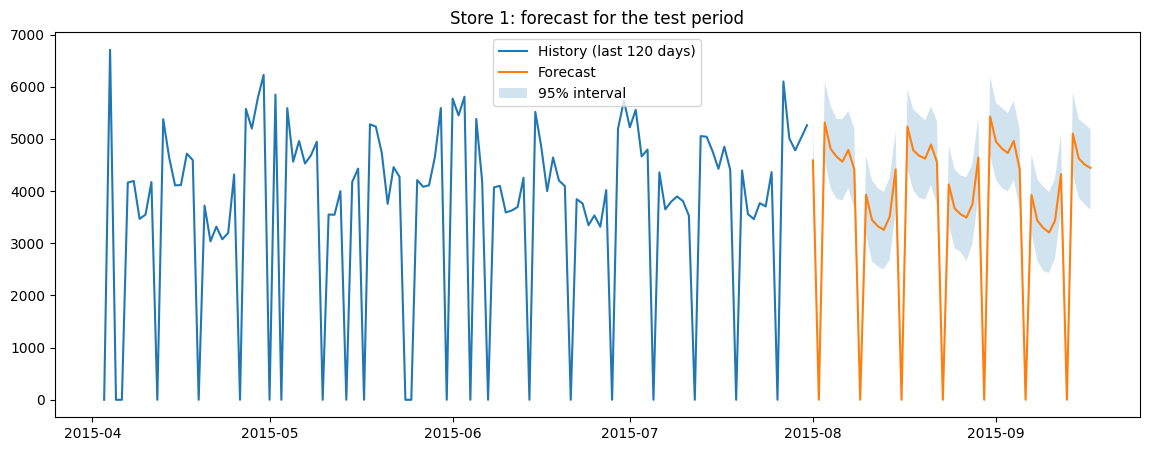

In [26]:
plt.figure(figsize=(14, 5))
hist = ts_df.iloc[-120:]
plt.plot(hist['ds'], hist['y'], label='History (last 120 days)')
plt.plot(test_s1['ds'], test_s1['Sales_forecast'], label='Forecast')
plt.fill_between(test_s1['ds'], test_s1['lower'], test_s1['upper'], alpha=0.2, label='95% interval')
plt.legend(); plt.title('Store 1: forecast for the test period')
plt.savefig(OUT / 'forecast_store1_test.png', dpi=120, bbox_inches='tight')
plt.show()

## Anomaly detection

The model from the validation experiment (trained only on the first 80% of history) forecasts the held-out window. A robust noise level (MAD-based sigma) is estimated from the model's residuals on **training** open days, and a held-out open day is flagged when its residual exceeds 2.5 sigma. Closed days are excluded because the store being shut is expected, not anomalous.

Prophet's own 95% interval was tried first and flagged about 17% of open days, far above the nominal 5%: it only reflects trend uncertainty and underestimates day-level noise. The residual-based threshold is better calibrated.

In [27]:
det = val_df.copy()
pf = prophet_reg.predict(det[['ds'] + regressors])
det['yhat'] = mask_closed(pf['yhat'].values, det['Open'])
det['residual'] = det['y'] - det['yhat']

# noise level from training residuals on open days (robust to outliers)
tr_pred = prophet_reg.predict(train_df[['ds'] + regressors])['yhat'].values
tr_res = (train_df['y'].values - tr_pred)[train_df['Open'].values == 1]
sigma = 1.4826 * np.median(np.abs(tr_res - np.median(tr_res)))
k = 2.5
det['lower'] = det['yhat'] - k * sigma
det['upper'] = det['yhat'] + k * sigma

open_days = det['Open'] == 1
det['anomaly'] = open_days & (det['residual'].abs() > k * sigma)
det['type'] = np.where(det['anomaly'] & (det['residual'] > 0), 'spike',
              np.where(det['anomaly'], 'drop', ''))

anomalies = det[det['anomaly']][['ds', 'y', 'yhat', 'lower', 'upper', 'residual', 'Promo', 'StateHoliday', 'type']]
anomalies.to_csv(OUT / 'anomalies_store1.csv', index=False)
print(f"sigma = {sigma:.0f}, threshold = +/-{k * sigma:.0f}")
print(f"{len(anomalies)} anomalies out of {int(open_days.sum())} open days ({100 * len(anomalies) / open_days.sum():.1f}%)")
anomalies.round(0)

sigma = 512, threshold = +/-1279
6 anomalies out of 156 open days (3.8%)


,ds,y,yhat,lower,upper,residual,Promo,StateHoliday,type
776,2015-02-16,4303,5728.0,4449.0,7007.0,-1425.0,1,0,drop
806,2015-03-18,3858,5262.0,3982.0,6541.0,-1404.0,1,0,drop
808,2015-03-20,4057,5452.0,4172.0,6731.0,-1395.0,1,0,drop
820,2015-04-01,6816,5179.0,3900.0,6459.0,1637.0,1,0,spike
821,2015-04-02,6574,5086.0,3807.0,6365.0,1488.0,1,0,spike
823,2015-04-04,6709,4966.0,3687.0,6245.0,1743.0,0,0,spike


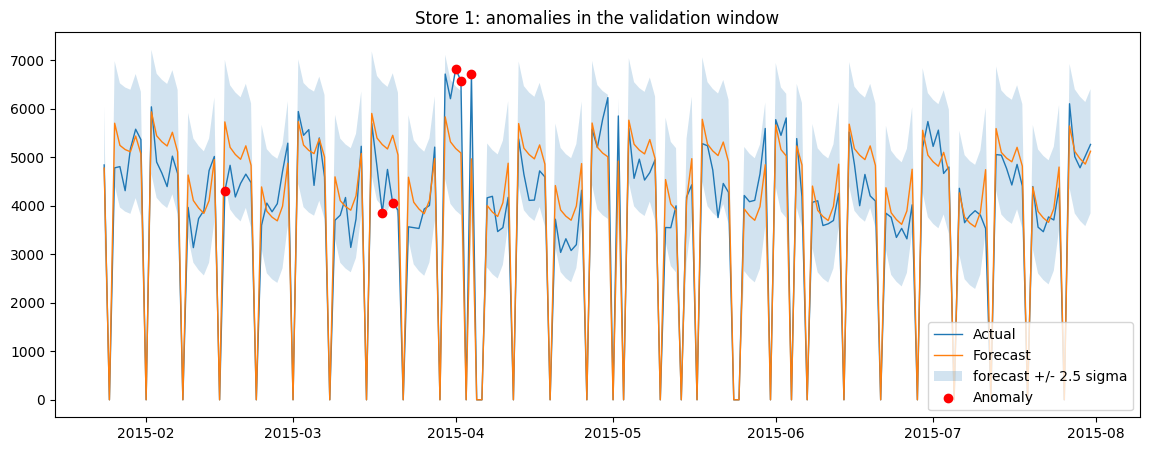

In [28]:
plt.figure(figsize=(14, 5))
plt.plot(det['ds'], det['y'], label='Actual', linewidth=1)
plt.plot(det['ds'], det['yhat'], label='Forecast', linewidth=1)
plt.fill_between(det['ds'], det['lower'].where(open_days, 0), det['upper'].where(open_days, 0), alpha=0.2, label='forecast +/- 2.5 sigma')
plt.scatter(det.loc[det['anomaly'], 'ds'], det.loc[det['anomaly'], 'y'], color='red', zorder=3, label='Anomaly')
plt.legend(); plt.title('Store 1: anomalies in the validation window')
plt.savefig(OUT / 'anomalies_store1.png', dpi=120, bbox_inches='tight')
plt.show()

Flagged days are candidates for investigation (stock-outs, local events, data-entry errors), not confirmed faults. The multiplier `k` trades false alarms against missed events and should be tuned with business input.